# Chapter 24: Symmetry, flat minima and normalisation

Checks [chapter 24](../../book/24-symmetry.md). Three models, all small and in float64, all seeded:
a **linear model in its weights** (a random 3 by 6 matrix) for rescaling, because `Reparam.lean` is about a linear
predictor; a **one-hidden-layer network with an RMSNorm** on the hidden layer for the right-angles claim, because
that is the loss `Symmetry.lean` and `RmsNorm.lean` are about; and the **product of two numbers** for the balance law.
These are measurements, not proofs: the proofs are in `Reparam.lean`, `Symmetry.lean` and `RmsNorm.lean`.
Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
import torch
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE
import matplotlib.pyplot as plt

use_style()
SEED = 24
torch.manual_seed(SEED)
generator = torch.Generator().manual_seed(SEED)

NUM_OUTPUTS, NUM_WEIGHTS = 3, 6
predict_matrix = torch.randn(NUM_OUTPUTS, NUM_WEIGHTS, generator=generator)
labels = torch.randn(NUM_OUTPUTS, generator=generator)
start_weights = torch.randn(NUM_WEIGHTS, generator=generator)
SCALES = [0.1, 0.25, 0.5, 1.0, 2.0, 4.0, 10.0, 30.0]


def rescale_predict(scale, matrix=predict_matrix):
    """RESCALE scale predict: the model divided by `scale`. Its parameters are `scale` times the old ones."""
    return matrix / scale


def get_residual(matrix, weights):
    return matrix @ weights - labels


def get_loss(matrix, weights):
    return get_residual(matrix, weights).pow(2).sum()


def get_sharpness(matrix, weights):
    """The top eigenvalue of the Hessian of the loss in the weights, by autograd."""
    hessian = torch.autograd.functional.hessian(lambda trial: get_loss(matrix, trial), weights)
    return float(torch.linalg.eigvalsh(hessian)[-1])


def get_travel_by_least_squares(matrix, weights):
    """Distance from `weights` to the nearest weights that give the labels exactly."""
    shift = torch.linalg.pinv(matrix) @ (labels - matrix @ weights)
    return float(shift.norm())


def get_travel_by_descent(matrix, weights, num_steps=20000):
    """Run gradient descent to convergence and measure how far the weights went."""
    learning_rate = 1.0 / float(torch.linalg.eigvalsh(2 * matrix.T @ matrix)[-1])
    current = weights.clone()
    for _ in range(num_steps):
        current = current - learning_rate * 2 * matrix.T @ get_residual(matrix, current)
    final_error = float(get_residual(matrix, current).norm())
    return float((current - weights).norm()), final_error

## Claim 1: rescaling keeps the error, divides the curvature by `scale²` and multiplies the travel by `|scale|` (`flatter_is_farther`)

The model is `predict_matrix @ weights`. Rescaling by `scale` gives the model `predict_matrix / scale`, started at
`scale * start_weights`. For `scale` from 0.1 to 30 I measure: the outputs and the residual at the start (**predicted**
equal to the old ones, to rounding); the **sharpness**, the top eigenvalue of the Hessian of the loss found by autograd
(**predicted** `sharpness(1) / scale²`); and the **travel**, the distance gradient descent actually goes, run to
convergence from the start (**predicted** `|scale| × travel(1)`, and equal to the least-squares answer).
Each prediction fails if a measured ratio is off by more than `1e-6` relative. Gradient descent must reach the labels
(final error below `1e-9`) or the travel is not the travel to a fit.

**The control** breaks the hypothesis: rescale only the first three weights by `scale` and leave the other three. The
outputs and the residual are still kept, but the rescaling is no longer one number, so I predict the curvature
ratio is **not** `1 / scale²` and the travel ratio is **not** `|scale|`. The check passes if the control is off by more than 10% at `scale = 10`.

In [2]:
sharpness_one = get_sharpness(rescale_predict(1.0), start_weights)
travel_one = get_travel_by_least_squares(rescale_predict(1.0), start_weights)
rows = []
worst_output_gap, worst_residual_gap = 0.0, 0.0
worst_sharpness_error, worst_travel_error, worst_method_gap, worst_final_error = 0.0, 0.0, 0.0, 0.0
for scale in SCALES:
    matrix = rescale_predict(scale)
    scaled_start = scale * start_weights
    worst_output_gap = max(worst_output_gap, float((matrix @ scaled_start - predict_matrix @ start_weights).abs().max()))
    worst_residual_gap = max(worst_residual_gap, float((get_residual(matrix, scaled_start) - get_residual(predict_matrix, start_weights)).abs().max()))
    sharpness = get_sharpness(matrix, scaled_start)
    travel_descent, final_error = get_travel_by_descent(matrix, scaled_start)
    travel_exact = get_travel_by_least_squares(matrix, scaled_start)
    worst_sharpness_error = max(worst_sharpness_error, abs(sharpness * scale ** 2 / sharpness_one - 1))
    worst_travel_error = max(worst_travel_error, abs(travel_descent / (abs(scale) * travel_one) - 1))
    worst_method_gap = max(worst_method_gap, abs(travel_descent / travel_exact - 1))
    worst_final_error = max(worst_final_error, final_error)
    rows.append((scale, sharpness, travel_descent))
print("scale   sharpness      travel (descent)")
for scale, sharpness, travel_descent in rows:
    print(f"{scale:6.2f}  {sharpness:12.5g}  {travel_descent:10.5f}")
report("rescaling keeps every output", worst_output_gap < 1e-10, f"largest output gap {worst_output_gap:.1e}")
report("rescaling keeps the residual", worst_residual_gap < 1e-10, f"largest residual gap {worst_residual_gap:.1e}")
report("sharpness times scale^2 is the same at all 8 scales", worst_sharpness_error < 1e-6, f"largest relative error {worst_sharpness_error:.1e}")
report("gradient descent reaches the labels at every scale", worst_final_error < 1e-9, f"largest final error {worst_final_error:.1e}")
report("travel over |scale| is the same at all 8 scales", worst_travel_error < 1e-6, f"largest relative error {worst_travel_error:.1e}")
report("descent travel agrees with the least-squares travel", worst_method_gap < 1e-6, f"largest relative gap {worst_method_gap:.1e}")

control_scale = 10.0
control_matrix = predict_matrix.clone()
control_matrix[:, :3] = control_matrix[:, :3] / control_scale
control_start = start_weights.clone()
control_start[:3] = control_start[:3] * control_scale
control_residual_gap = float((get_residual(control_matrix, control_start) - get_residual(predict_matrix, start_weights)).abs().max())
control_sharpness_ratio = get_sharpness(control_matrix, control_start) * control_scale ** 2 / sharpness_one
control_travel_ratio = get_travel_by_least_squares(control_matrix, control_start) / (control_scale * travel_one)
report("control: rescaling only half the weights still keeps the residual", control_residual_gap < 1e-10, f"gap {control_residual_gap:.1e}")
report("control: the sharpness law breaks", abs(control_sharpness_ratio - 1) > 0.1, f"sharpness times scale^2 over the old sharpness is {control_sharpness_ratio:.3f}, not 1")
report("control: the travel law breaks", abs(control_travel_ratio - 1) > 0.1, f"travel over (scale times old travel) is {control_travel_ratio:.3f}, not 1")

scale   sharpness      travel (descent)
  0.10        1274.8     0.13615
  0.25        203.97     0.34038
  0.50        50.992     0.68076
  1.00        12.748     1.36153
  2.00         3.187     2.72306
  4.00       0.79675     5.44612
 10.00       0.12748    13.61529
 30.00      0.014164    40.84588
[PASS] rescaling keeps every output  (largest output gap 2.2e-16)
[PASS] rescaling keeps the residual  (largest residual gap 2.2e-16)
[PASS] sharpness times scale^2 is the same at all 8 scales  (largest relative error 2.2e-16)
[PASS] gradient descent reaches the labels at every scale  (largest final error 1.1e-16)
[PASS] travel over |scale| is the same at all 8 scales  (largest relative error 5.6e-16)
[PASS] descent travel agrees with the least-squares travel  (largest relative gap 4.4e-16)
[PASS] control: rescaling only half the weights still keeps the residual  (gap 2.2e-16)
[PASS] control: the sharpness law breaks  (sharpness times scale^2 over the old sharpness is 52.386, not 1)
[PAS

True

wrote book/figures/24-flatter-is-farther.png


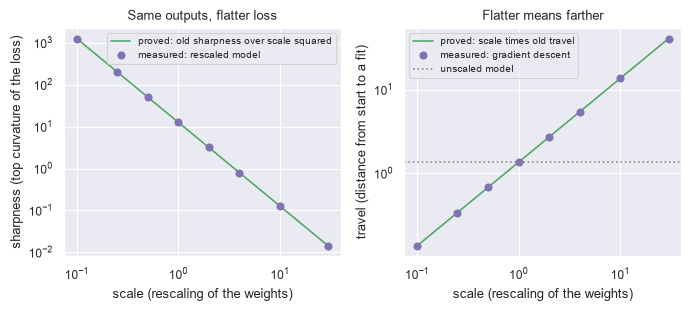

In [3]:
fig, (left_axis, right_axis) = plt.subplots(1, 2, figsize=(7, 3.2))
scales = np.array([row[0] for row in rows])
measured_sharpness = np.array([row[1] for row in rows])
measured_travel = np.array([row[2] for row in rows])
left_axis.loglog(scales, sharpness_one / scales ** 2, color=BOUND, label="proved: old sharpness over scale squared")
left_axis.loglog(scales, measured_sharpness, "o", color=MODEL, label="measured: rescaled model")
left_axis.set_xlabel("scale (rescaling of the weights)")
left_axis.set_ylabel("sharpness (top curvature of the loss)")
left_axis.set_title("Same outputs, flatter loss")
left_axis.legend(fontsize=7)
right_axis.loglog(scales, abs(scales) * travel_one, color=BOUND, label="proved: scale times old travel")
right_axis.loglog(scales, measured_travel, "o", color=MODEL, label="measured: gradient descent")
right_axis.axhline(travel_one, color=BEFORE, linestyle=":", label="unscaled model")
right_axis.set_xlabel("scale (rescaling of the weights)")
right_axis.set_ylabel("travel (distance from start to a fit)")
right_axis.set_title("Flatter means farther")
right_axis.legend(fontsize=7)
fig.tight_layout()
save_figure(fig, "24-flatter-is-farther")
plt.show()

### The worked example, and the one-step law (`strength_mul_travel_sq`, `gradientStep_rescale`)

The chapter's example: the model `2 × weight`, label 4, start 0, rescaled by 10. **Predicted** (exact arithmetic):
travel 2 then 20, kernel 4 then 0.04, and strength times travel squared 16 both times, equal to the error squared.
The check fails if any differs. Then, at the 8 scales, a step of the rescaled model with `learning_rate` is predicted
to be a step of the old model with `learning_rate / scale²`, to rounding.

In [4]:
for scale in (1.0, 10.0):
    slope = 2.0 / scale
    travel = abs(4.0 / slope)
    kernel = slope * slope
    print(f"scale {scale:4.1f}: travel {travel:.4g}, kernel {kernel:.4g}, kernel times travel squared {kernel * travel ** 2:.4g}")
    report(f"example at scale {scale:g}: kernel times travel squared is the error squared", abs(kernel * travel ** 2 - 4.0 ** 2) < 1e-9)
report("example: travel 2 becomes 20", abs(abs(4.0 / (2.0 / 10.0)) - 20.0) < 1e-12 and abs(abs(4.0 / 2.0) - 2.0) < 1e-12)

worst_step_gap = 0.0
for scale in SCALES:
    learning_rate = 0.05
    matrix = rescale_predict(scale)
    stepped = scale * start_weights - learning_rate * 2 * matrix.T @ get_residual(matrix, scale * start_weights)
    old_step = start_weights - (learning_rate / scale ** 2) * 2 * predict_matrix.T @ get_residual(predict_matrix, start_weights)
    worst_step_gap = max(worst_step_gap, float((stepped / scale - old_step).abs().max()))
report("a rescaled step is an old step with learning_rate / scale^2, at 8 scales", worst_step_gap < 1e-10, f"largest gap {worst_step_gap:.1e}")

scale  1.0: travel 2, kernel 4, kernel times travel squared 16
[PASS] example at scale 1: kernel times travel squared is the error squared
scale 10.0: travel 20, kernel 0.04, kernel times travel squared 16
[PASS] example at scale 10: kernel times travel squared is the error squared
[PASS] example: travel 2 becomes 20
[PASS] a rescaled step is an old step with learning_rate / scale^2, at 8 scales  (largest gap 7.1e-15)


True

## Claim 2: for a loss that ignores the scale of the weights, the gradient is at right angles to the weights, and a step adds its squared length to the squared length of the weights (`inner_gradient_self_eq_zero`, `norm_sq_sub_smul_of_inner_eq_zero`)

The model is a one-hidden-layer network, `readout @ normalize_by_rms(hidden_weights @ input)`, with `normalize_by_rms`
dividing by the root mean square (no epsilon, as in `RmsNorm.lean`). Its loss is scale invariant in `hidden_weights`.
Seeded: 20 inputs of size 6, 8 hidden units, 3 outputs, a fixed readout. I measure:

- the loss at `c × hidden_weights` for `c` from 0.3 to 7 (**predicted** equal to the loss at `c = 1`);
- the cosine between the gradient and the weights at 100 random weight settings (**predicted** 0 to rounding);
- 300 steps of gradient descent: after each, squared length minus the old squared length minus `learning_rate² ×
  ‖gradient‖²` (**predicted** 0 to rounding), and the length never decreasing.

**The control** is the same network with the normalisation left out. I predict the cosine is far from 0, and that
the length shrinks on at least one step from a start with long weights. The check passes if the control cosine is above 0.1 somewhere and the length falls by more than 0.1.

In [5]:
NUM_SAMPLES, NUM_INPUTS, NUM_HIDDEN, NUM_TARGETS = 20, 6, 8, 3
inputs = torch.randn(NUM_SAMPLES, NUM_INPUTS, generator=generator)
targets = torch.randn(NUM_SAMPLES, NUM_TARGETS, generator=generator)
readout = torch.randn(NUM_TARGETS, NUM_HIDDEN, generator=generator)


def normalize_by_rms(vectors):
    """vector / sqrt(mean(vector ** 2)), no epsilon."""
    return vectors / vectors.pow(2).mean(dim=-1, keepdim=True).sqrt()


def get_network_loss(flat_weights, use_norm):
    hidden = inputs @ flat_weights.reshape(NUM_HIDDEN, NUM_INPUTS).T
    if use_norm:
        hidden = normalize_by_rms(hidden)
    return (hidden @ readout.T - targets).pow(2).mean()


def get_gradient(flat_weights, use_norm):
    trial = flat_weights.clone().requires_grad_(True)
    get_network_loss(trial, use_norm).backward()
    return trial.grad.detach()


base_weights = torch.randn(NUM_HIDDEN * NUM_INPUTS, generator=generator)
base_loss = float(get_network_loss(base_weights, True))
scale_gap = max(abs(float(get_network_loss(factor * base_weights, True)) - base_loss) / base_loss for factor in (0.3, 0.7, 2.0, 7.0))
report("the normalised loss ignores the scale of the weights", scale_gap < 1e-10, f"largest relative change {scale_gap:.1e}")


def get_largest_cosine(use_norm):
    worst = 0.0
    for _ in range(100):
        weights = torch.randn(NUM_HIDDEN * NUM_INPUTS, generator=generator) * float(torch.rand(1, generator=generator) * 3 + 0.2)
        gradient = get_gradient(weights, use_norm)
        worst = max(worst, abs(float(gradient @ weights / (gradient.norm() * weights.norm()))))
    return worst


normalised_cosine, plain_cosine = get_largest_cosine(True), get_largest_cosine(False)
report("normalised network: gradient is at right angles to the weights (100 settings)", normalised_cosine < 1e-10, f"largest |cosine| {normalised_cosine:.1e}")
report("control: without the norm the gradient is not at right angles", plain_cosine > 0.1, f"largest |cosine| {plain_cosine:.3f}")

NUM_STEPS, LEARNING_RATE = 300, 0.1
histories = {}
for use_norm in (True, False):
    weights = 3.0 * base_weights.clone()
    lengths = [float(weights.norm())]
    predicted = [lengths[0]]
    worst_pythagoras = 0.0
    for _ in range(NUM_STEPS):
        gradient = get_gradient(weights, use_norm)
        new_weights = weights - LEARNING_RATE * gradient
        added = float(new_weights.norm() ** 2 - weights.norm() ** 2)
        step_squared = LEARNING_RATE ** 2 * float(gradient.norm() ** 2)
        worst_pythagoras = max(worst_pythagoras, abs(added - step_squared) / max(step_squared, 1e-300))
        predicted.append(float(np.sqrt(predicted[-1] ** 2 + step_squared)))
        weights = new_weights
        lengths.append(float(weights.norm()))
    histories[use_norm] = (np.array(lengths), np.array(predicted), worst_pythagoras)
lengths, predicted, worst_pythagoras = histories[True]
report("normalised: the squared length grows by exactly the squared step, over 300 steps", worst_pythagoras < 1e-6, f"largest relative gap {worst_pythagoras:.1e}")
report("normalised: the weights never get shorter", bool((np.diff(lengths) >= -1e-12).all()), f"smallest change {np.diff(lengths).min():.1e}")
report("normalised: the length stays on the Pythagoras curve built from the measured steps", np.abs(lengths - predicted).max() < 1e-6, f"largest gap {np.abs(lengths - predicted).max():.1e}")
plain_lengths = histories[False][0]
report("control: without the norm the weights shrink", plain_lengths.min() < plain_lengths[0] - 0.1,
       f"length falls from {plain_lengths[0]:.3f} to a low of {plain_lengths.min():.3f}")
print(f"normalised length: {lengths[0]:.4f} at step 0, {lengths[-1]:.4f} at step {NUM_STEPS}")

[PASS] the normalised loss ignores the scale of the weights  (largest relative change 0.0e+00)


[PASS] normalised network: gradient is at right angles to the weights (100 settings)  (largest |cosine| 7.1e-17)
[PASS] control: without the norm the gradient is not at right angles  (largest |cosine| 0.654)


[PASS] normalised: the squared length grows by exactly the squared step, over 300 steps  (largest relative gap 7.0e-10)
[PASS] normalised: the weights never get shorter  (smallest change 7.9e-06)
[PASS] normalised: the length stays on the Pythagoras curve built from the measured steps  (largest gap 1.8e-14)
[PASS] control: without the norm the weights shrink  (length falls from 20.531 to a low of 15.676)
normalised length: 20.5310 at step 0, 20.5391 at step 300


wrote book/figures/24-weights-only-grow.png


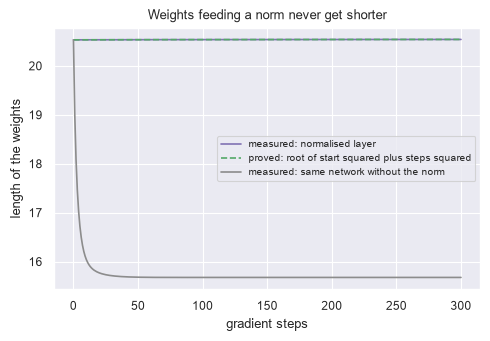

In [6]:
fig, axis = plt.subplots(figsize=(5.5, 3.4))
steps = np.arange(NUM_STEPS + 1)
axis.plot(steps, histories[True][0], color=MODEL, label="measured: normalised layer")
axis.plot(steps, histories[True][1], color=BOUND, linestyle="--", label="proved: root of start squared plus steps squared")
axis.plot(steps, histories[False][0], color=BEFORE, label="measured: same network without the norm")
axis.set_xlabel("gradient steps")
axis.set_ylabel("length of the weights")
axis.set_title("Weights feeding a norm never get shorter")
axis.legend(fontsize=7)
save_figure(fig, "24-weights-only-grow")
plt.show()

## Claim 3: one step multiplies the imbalance by `1 - learning_rate² × error²` (`balance_after_step`)

The model is `first_weight × second_weight`, loss half the squared error. **Predicted:**
across 1000 random starts, labels and step sizes the imbalance after one step equals the formula, to rounding;
the chapter's by-hand numbers give 8 then 7.28 and, in check-yourself, 6; and equal weights stay equal over 200 steps.
**Control:** add weight decay of 0.1 to each step, which the theorem does not cover. I predict the formula then
misses, and the check passes if it is off by more than 1e-3 relative on average.

In [7]:
def take_product_step(first_weight, second_weight, label, learning_rate, decay=0.0):
    error = first_weight * second_weight - label
    new_first = first_weight - learning_rate * (error * second_weight + decay * first_weight)
    new_second = second_weight - learning_rate * (error * first_weight + decay * second_weight)
    return new_first, new_second, error


worst_formula_gap, decay_miss = 0.0, 0.0
for _ in range(1000):
    first, second, label = (float(value) for value in torch.randn(3, generator=generator))
    learning_rate = float(torch.rand(1, generator=generator)) * 0.5
    new_first, new_second, error = take_product_step(first, second, label, learning_rate)
    before, after = first ** 2 - second ** 2, new_first ** 2 - new_second ** 2
    worst_formula_gap = max(worst_formula_gap, abs(after - before * (1 - learning_rate ** 2 * error ** 2)))
    decayed_first, decayed_second, _ = take_product_step(first, second, label, learning_rate, decay=0.1)
    decay_miss += abs(decayed_first ** 2 - decayed_second ** 2 - before * (1 - learning_rate ** 2 * error ** 2)) / (abs(before) + 1e-12) / 1000
report("imbalance after one step matches the formula, 1000 random cases", worst_formula_gap < 1e-12, f"largest gap {worst_formula_gap:.1e}")
new_first, new_second, error = take_product_step(3.0, 1.0, 0.0, 0.1)
report("by hand: weights 3 and 1 become 2.7 and 0.1, imbalance 8 becomes 7.28", abs(new_first - 2.7) < 1e-12 and abs(new_second - 0.1) < 1e-12 and abs(new_first ** 2 - new_second ** 2 - 7.28) < 1e-12)
new_first, new_second, error = take_product_step(3.0, 1.0, 2.0, 0.5)
report("check yourself: imbalance after one step is 6", abs(new_first ** 2 - new_second ** 2 - 6.0) < 1e-12, f"measured {new_first ** 2 - new_second ** 2:.6f}")
first = second = 1.7
worst_imbalance = 0.0
for _ in range(200):
    first, second, _ = take_product_step(first, second, 1.0, 0.1)
    worst_imbalance = max(worst_imbalance, abs(first - second))
report("balanced stays balanced over 200 steps", worst_imbalance < 1e-12, f"largest gap between the weights {worst_imbalance:.1e}")
report("control: with weight decay the formula misses", decay_miss > 1e-3, f"mean relative miss {decay_miss:.3f}")

[PASS] imbalance after one step matches the formula, 1000 random cases  (largest gap 3.6e-15)
[PASS] by hand: weights 3 and 1 become 2.7 and 0.1, imbalance 8 becomes 7.28
[PASS] check yourself: imbalance after one step is 6  (measured 6.000000)
[PASS] balanced stays balanced over 200 steps  (largest gap between the weights 0.0e+00)
[PASS] control: with weight decay the formula misses  (mean relative miss 0.050)


True

## Claim 4: RMSNorm forgets the scale, and shuffling hidden units gives the same function (`normalizeByRms_smul`, `oneHiddenLayer_relabel`)

**Predicted:** `normalize_by_rms(c × vector) = normalize_by_rms(vector)` for positive `c` to rounding, and the output has
root mean square 1; a random permutation of the hidden units (rows of the first layer and columns of the readout together)
gives the same outputs on all 20 inputs. **Control:** a negative `c` is outside the theorem (`0 < scale`): I predict the sign flips,
so the output differs from the old one. The check passes if the gap is at least 1.

In [8]:
vectors = torch.randn(50, NUM_HIDDEN, generator=generator)
scale_gap = max(float((normalize_by_rms(factor * vectors) - normalize_by_rms(vectors)).abs().max()) for factor in (0.01, 0.5, 3.0, 1000.0))
mean_square_gap = float((normalize_by_rms(vectors).pow(2).mean(dim=-1).sqrt() - 1).abs().max())
negative_gap = float((normalize_by_rms(-2.0 * vectors) - normalize_by_rms(vectors)).abs().max())
report("RMSNorm ignores a positive scale, from 0.01 to 1000", scale_gap < 1e-10, f"largest gap {scale_gap:.1e}")
report("RMSNorm output has root mean square 1", mean_square_gap < 1e-12, f"largest gap {mean_square_gap:.1e}")
report("control: a negative scale flips the output", negative_gap > 1.0, f"largest gap {negative_gap:.3f}")

first_layer = torch.randn(NUM_HIDDEN, NUM_INPUTS, generator=generator)
permutation = torch.randperm(NUM_HIDDEN, generator=generator)


def run_one_hidden_layer(first, last):
    return torch.relu(inputs @ first.T) @ last.T


relabel_gap = float((run_one_hidden_layer(first_layer, readout) - run_one_hidden_layer(first_layer[permutation], readout[:, permutation])).abs().max())
report("shuffling hidden units keeps the function", relabel_gap < 1e-12, f"largest output gap {relabel_gap:.1e}")

[PASS] RMSNorm ignores a positive scale, from 0.01 to 1000  (largest gap 4.4e-16)
[PASS] RMSNorm output has root mean square 1  (largest gap 2.2e-16)
[PASS] control: a negative scale flips the output  (largest gap 4.655)
[PASS] shuffling hidden units keeps the function  (largest output gap 1.8e-15)


True